# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY

#### [Setup] 1. Khai báo thư viện & Cố định ngẫu nhiên

In [69]:
pip install numpy pandas matplotlib torch rouge-score sacrebleu

Note: you may need to restart the kernel to use updated packages.


In [70]:
import hashlib, json, random, time, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import json
import re

import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

# Các token đặc biệt
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def setup_env(data_path):
    seed_all(42)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    data_dir = Path(data_path)
    print('PyTorch:', torch.__version__, '| Device:', device)
    print('Thư mục dữ liệu:', data_dir)
    return device, data_dir

DATA_DIR = Path("/kaggle/input/datasets/xuancuong1019/phomt-dataset")
device, DATA = setup_env(DATA_DIR)

PyTorch: 2.11.0+cu130 | Device: cuda
Thư mục dữ liệu: /kaggle/input/datasets/xuancuong1019/phomt-dataset


#### [Setup] 2. Thiết lập cấu hình thực nghiệm 

In [71]:
# Cấu hình thực nghiệm
def get_config():
    return {
        'emb': 256,
        'hidden': 256,
        'layers': 3,
        'dropout': 0.3,
        'batch': 32,
        'lr': 1e-3,
        'teacher_ratio': 0.5,
        'epochs': 10,
        'max_words': 50,
        'vocab_limit': 10000,
        'min_freq': 2,
        'train_limit': None,
        'dev_limit': None
    }

cfg = get_config()

#### [Setup] 3. Tải dữ liệu & Kiểm tra toàn vẹn SHA-256

In [73]:
# Kiểm tra sự tồn tại và toàn vẹn dữ liệu (SHA-256)
EXPECTED_HASHES = {
    'small-train.json': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba',
    'small-dev.json':   'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9',
    'small-test.json':  '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'
}

def verify_dataset_files(data_dir, hash_dict):
    for filename, expected_sha in hash_dict.items():
        file_path = data_dir / filename
        if not file_path.exists():
            raise FileNotFoundError(f"Không tìm thấy file: {file_path}")
        
        file_bytes = file_path.read_bytes()
        actual_sha = hashlib.sha256(file_bytes).hexdigest()
        
        if actual_sha != expected_sha:
            raise ValueError(f"File {filename} bị lỗi hoặc không đúng chuẩn SHA-256!")
            
    print("Kiểm tra hoàn tất: Cả 3 file dữ liệu đều hợp lệ.")

verify_dataset_files(DATA_DIR, EXPECTED_HASHES)

Kiểm tra hoàn tất: Cả 3 file dữ liệu đều hợp lệ.


#### [Data] 4. Tiền xử lý & Lọc độ dài câu

In [74]:
# Bỏ BOM -> Thống nhất một dạng unicode -> Chuyền thành chữ thường -> Tách theo khoảng trắng
def tokens(text):
    text = text.replace('\ufeff', '')
    text = unicodedata.normalize('NFC', text).lower()
    return text.split()
# Lọc các cặp câu có độ dài không nằm trong [1, max_words]
def load_and_filter_data(data_dir, max_words):
    raw, filtered = {}, {}
    for split in ['train', 'dev', 'test']:
        path = data_dir / f'small-{split}.json'
        raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
        filtered[split] = []
        
        for i, row in enumerate(raw[split]):
            src = tokens(row['english'])
            tgt = tokens(row['vietnamese'])
            if 1 <= len(src) <= max_words and 1 <= len(tgt) <= max_words:
                filtered[split].append(dict(id=i, src=src, tgt=tgt))
                
        print(f"{split:5} | tệp gốc: {len(raw[split]):5} | sau lọc: {len(filtered[split]):5}")
    return raw, filtered

# Kiểm tra kích thước dữ liệu
def check_dataset(raw, filtered):
    assert [len(raw[s]) for s in ['train', 'dev', 'test']] == [20000, 2000, 2000]
    assert all(filtered[s] for s in filtered)
    print('Đúng schema và ba bộ chia gốc: PASS')

# Thực thi
raw, filtered = load_and_filter_data(DATA, cfg['max_words'])
check_dataset(raw, filtered)

train | tệp gốc: 20000 | sau lọc: 18607
dev   | tệp gốc:  2000 | sau lọc:  1901
test  | tệp gốc:  2000 | sau lọc:  1786
Đúng schema và ba bộ chia gốc: PASS


#### [Vocab & Batch] 5. Xây dựng từ điển

In [75]:
# Xây dựng từ điển 
def build_vocabulary(token_lists, min_freq, max_vocab_size):
    word_counts = Counter()
    for seq in token_lists:
        word_counts.update(seq)
        
    valid_words = [
        word for word, count in word_counts.items()
        if count >= min_freq and word not in SPECIAL_TOKENS
    ]
    
    valid_words.sort(key=lambda w: (-word_counts[w], w))
    selected_words = valid_words[:max_vocab_size - len(SPECIAL_TOKENS)]
    vocab = {tok: idx for idx, tok in enumerate(SPECIAL_TOKENS + selected_words)}
    return vocab

# Đổi token thành id
def tokens_to_ids(seq, vocab):
    return [vocab.get(word, UNK) for word in seq]

# Đổi id thành token
def ids_to_text(id_seq, id_to_word):
    result = []
    for idx in id_seq:
        idx = int(idx)
        if idx == EOS:
            break
        if idx not in (PAD, BOS):
            result.append(id_to_word[idx])
    return ' '.join(result)

# Xây dựng từ điển nguồn và từ điển đích
src_vocab = build_vocabulary(
    [item['src'] for item in filtered['train']], 
    cfg['min_freq'], 
    cfg['vocab_limit']
)
tgt_vocab = build_vocabulary(
    [item['tgt'] for item in filtered['train']], 
    cfg['min_freq'], 
    cfg['vocab_limit']
)
tgt_itos = {idx: tok for tok, idx in tgt_vocab.items()}

# Kiểm tra
assert all(src_vocab[t] == tgt_vocab[t] == i for i, t in enumerate(SPECIAL_TOKENS))
print(f"Kích thước từ điển Anh / Việt: {len(src_vocab)} / {len(tgt_vocab)}")

Kích thước từ điển Anh / Việt: 8943 / 4003


#### [Vocab & Batch] 6. Đóng gói Batch & Khởi tạo DataLoader

In [76]:
# Đóng gói danh sách các mẫu thành một batch (thêm BOS/EOS và đệm PAD)
def collate_batch(samples):
    src_tensors, tgt_tensors = [], []
    src_lengths, ref_texts, sample_ids = [], [], []
    
    for item in samples:
        # Câu nguồn thêm EOS ở cuối; câu đích thêm cả BOS ở đầu và EOS ở cuối
        s_ids = tokens_to_ids(item['src'], src_vocab) + [EOS]
        t_ids = [BOS] + tokens_to_ids(item['tgt'], tgt_vocab) + [EOS]
        
        src_tensors.append(torch.tensor(s_ids, dtype=torch.long))
        tgt_tensors.append(torch.tensor(t_ids, dtype=torch.long))
        src_lengths.append(len(s_ids))
        ref_texts.append(' '.join(item['tgt']))
        sample_ids.append(item['id'])
        
    return {
        'src': pad_sequence(src_tensors, batch_first=True, padding_value=PAD),
        'lengths': torch.tensor(src_lengths, dtype=torch.long),
        'tgt': pad_sequence(tgt_tensors, batch_first=True, padding_value=PAD),
        'refs': ref_texts,
        'ids': sample_ids
    }

# Chọn tập con dữ liệu (nếu limit=None thì lấy toàn bộ cho Phần C)
def select_data_subset(data_rows, limit=None, seed=42):
    if limit is None or len(data_rows) <= limit:
        return data_rows
    rng = np.random.default_rng(seed)
    chosen_indices = rng.permutation(len(data_rows))[:limit]
    return [data_rows[int(i)] for i in chosen_indices]

# Tạo DataLoader với seed cố định để thứ tự batch đồng nhất giữa 3 mô hình
def get_dataloader(data_rows, shuffle=False, seed=42):
    gen = torch.Generator()
    gen.manual_seed(seed)
    return DataLoader(
        data_rows,
        batch_size=cfg['batch'],
        shuffle=shuffle,
        collate_fn=collate_batch,
        generator=gen
    )

# Thực thi chuẩn bị dữ liệu
train_rows = select_data_subset(filtered['train'], cfg['train_limit'])
dev_rows = select_data_subset(filtered['dev'], cfg['dev_limit'])

sample_batch = collate_batch(train_rows[:2])
print(f"Số cặp câu sử dụng -> Train: {len(train_rows)} | Dev: {len(dev_rows)}")
print(f"Số batch mỗi epoch (Train): {len(get_dataloader(train_rows))}")

Số cặp câu sử dụng -> Train: 18607 | Dev: 1901
Số batch mỗi epoch (Train): 582


#### [Architecture] 7. Định nghĩa lớp Encoder (LSTM Packing)

In [77]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

    def forward(self, src, lengths):
        embedded = self.dropout(self.embedding(src))
        
        # Đóng gói bỏ qua PAD khi đưa qua LSTM
        packed_in = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, final_state = self.lstm(packed_in)
        
        # Mở gói trả lại kích thước chuẩn [Batch, Seq_len, Hidden]
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1)
        )
        return memory, final_state

# Hàm kiểm tra kích thước đầu ra của Encoder
def test_encoder_module():
    enc = Encoder(len(src_vocab), cfg['emb'], cfg['hidden'], cfg['layers'], cfg['dropout']).to(device)
    mem, (h_n, c_n) = enc(sample_batch['src'].to(device), sample_batch['lengths'])
    print("Encoder Output -> Memory shape:", tuple(mem.shape), "| State h/c shape:", tuple(h_n.shape))
    return mem, (h_n, c_n)

_mem_test, _state_test = test_encoder_module()

Encoder Output -> Memory shape: (2, 21, 256) | State h/c shape: (3, 2, 256)


#### [Architecture] 8. Định nghĩa lớp Attention (Bahdanau & Luong)

In [78]:
class Attention(nn.Module):
    def __init__(self, hidden_dim, attn_type):
        super().__init__()
        self.attn_type = attn_type
        
        if attn_type == 'bahdanau':
            self.proj_query = nn.Linear(hidden_dim, hidden_dim, bias=False)
            self.proj_key = nn.Linear(hidden_dim, hidden_dim, bias=False)
            self.score_vec = nn.Linear(hidden_dim, 1, bias=False)
        elif attn_type == 'luong':
            self.proj_general = nn.Linear(hidden_dim, hidden_dim, bias=False)
        else:
            raise ValueError(f"Loại attention không hợp lệ: {attn_type}")

    def forward(self, query, memory, src_mask):
        if self.attn_type == 'bahdanau':
            # Điểm cộng: v^T * tanh(Wq * q + Wk * k)
            q_expanded = self.proj_query(query).unsqueeze(1)
            k_projected = self.proj_key(memory)
            energy = torch.tanh(q_expanded + k_projected)
            raw_scores = self.score_vec(energy).squeeze(-1)
        else:
            # Điểm nhân (Luong general): q^T * W * k
            k_projected = self.proj_general(memory)
            raw_scores = torch.bmm(k_projected, query.unsqueeze(2)).squeeze(2)

        # Gán -inf cho các vị trí PAD trước khi tính Softmax
        masked_scores = raw_scores.masked_fill(~src_mask, float('-inf'))
        attn_weights = torch.softmax(masked_scores, dim=-1)
        
        # Tính vector ngữ cảnh (Context = tổng trọng số của memory)
        context_vec = torch.bmm(attn_weights.unsqueeze(1), memory).squeeze(1)
        return context_vec, attn_weights

# Hàm kiểm tra cơ chế Masking của Attention
def test_attention_module(memory, state_h):
    src_mask = sample_batch['src'].to(device) != PAD
    for mode in ['bahdanau', 'luong']:
        attn_layer = Attention(cfg['hidden'], mode).to(device)
        ctx, w = attn_layer(state_h[-1], memory, src_mask)
        assert torch.allclose(w.sum(dim=-1), torch.ones(w.size(0), device=device))
        assert torch.all(w.masked_select(~src_mask) == 0)
        print(f"Attention [{mode:8}] -> Context shape: {tuple(ctx.shape)} | Masking check: PASS")

test_attention_module(_mem_test, _state_test[0])

Attention [bahdanau] -> Context shape: (2, 256) | Masking check: PASS
Attention [luong   ] -> Context shape: (2, 256) | Masking check: PASS


#### [Architecture] 9. Định nghĩa lớp Decoder & Seq2Seq

In [79]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, attn_type, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.attn_type = attn_type
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        
        # Nếu dùng attention thì đầu vào LSTM được nối thêm context hoặc feeding
        lstm_in_dim = emb_dim if attn_type == 'none' else emb_dim + hidden_dim
        self.lstm = nn.LSTM(
            input_size=lstm_in_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        if attn_type != 'none':
            self.attention = Attention(hidden_dim, attn_type)
            self.concat_proj = nn.Linear(hidden_dim * 2, hidden_dim)
            
        self.out_proj = nn.Linear(hidden_dim, vocab_size)

    def forward_step(self, input_token, hidden_state, memory, src_mask, prev_feeding):
        emb = self.dropout(self.embedding(input_token))
        attn_weights = None

        # Chuẩn bị đầu vào cho LSTM tùy theo cơ chế Attention
        if self.attn_type == 'bahdanau':
            top_hidden = hidden_state[0][-1]
            context, attn_weights = self.attention(top_hidden, memory, src_mask)
            rnn_in = torch.cat([emb, context], dim=-1)
        elif self.attn_type == 'luong':
            rnn_in = torch.cat([emb, prev_feeding], dim=-1)
        else:
            rnn_in = emb

        # Chạy 1 bước qua LSTM
        lstm_out, next_state = self.lstm(rnn_in.unsqueeze(1), hidden_state)
        step_vec = lstm_out[:, 0]

        # Luong tính attention sau khi LSTM cập nhật trạng thái
        if self.attn_type == 'luong':
            context, attn_weights = self.attention(step_vec, memory, src_mask)

        # Kết hợp trạng thái hiện tại và context
        if self.attn_type != 'none':
            combined = torch.cat([step_vec, context], dim=-1)
            next_feeding = torch.tanh(self.concat_proj(combined))
            step_vec = next_feeding
        else:
            next_feeding = prev_feeding

        logits = self.out_proj(self.dropout(step_vec))
        return logits, next_state, next_feeding, attn_weights


class Seq2Seq(nn.Module):
    def __init__(self, attn_type, src_vocab_size, tgt_vocab_size, emb_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.attn_type = attn_type
        self.hidden_dim = hidden_dim
        self.encoder = Encoder(src_vocab_size, emb_dim, hidden_dim, num_layers, dropout)
        self.decoder = Decoder(tgt_vocab_size, attn_type, emb_dim, hidden_dim, num_layers, dropout)

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        batch_size, tgt_len = src.size(0), tgt.size(1)
        memory, state = self.encoder(src, lengths)
        src_mask = (src != PAD)
        
        curr_token = tgt[:, 0]  # Bắt đầu từ token <bos>
        feeding_vec = memory.new_zeros(batch_size, self.hidden_dim)
        all_logits = []

        for t in range(1, tgt_len):
            step_logits, state, feeding_vec, _ = self.decoder.forward_step(
                curr_token, state, memory, src_mask, feeding_vec
            )
            all_logits.append(step_logits)
            
            # Quyết định Teacher Forcing cho bước tiếp theo
            use_teacher = torch.rand(batch_size, device=src.device) < teacher_ratio
            top_pred = step_logits.argmax(dim=-1).detach()
            curr_token = torch.where(use_teacher, tgt[:, t], top_pred)

        return torch.stack(all_logits, dim=1)

# Hàm khởi tạo nhanh mô hình theo chế độ
def build_seq2seq_model(attn_type, custom_cfg=None):
    c = custom_cfg if custom_cfg is not None else cfg
    model = Seq2Seq(
        attn_type=attn_type,
        src_vocab_size=len(src_vocab),
        tgt_vocab_size=len(tgt_vocab),
        emb_dim=c['emb'],
        hidden_dim=c['hidden'],
        num_layers=c['layers'],
        dropout=c['dropout']
    )
    return model.to(device)

#### [Inference & Check] 10. Giải mã Greedy & Kiểm chuẩn Padding/Loss

In [80]:
# Giải mã tham lam (Greedy Decoding) hoàn toàn không sử dụng câu đích
@torch.no_grad()
def greedy_decode(model, src, lengths, max_steps):
    model.eval()
    batch_size = src.size(0)
    memory, state = model.encoder(src, lengths)
    src_mask = (src != PAD)

    curr_token = torch.full((batch_size,), BOS, dtype=torch.long, device=src.device)
    feeding_vec = memory.new_zeros(batch_size, model.hidden_dim)
    is_finished = torch.zeros(batch_size, dtype=torch.bool, device=src.device)

    pred_tokens, attn_matrices = [], []

    for _ in range(max_steps):
        logits, state, feeding_vec, step_weights = model.decoder.forward_step(
            curr_token, state, memory, src_mask, feeding_vec
        )
        # Cấm mô hình sinh ra token PAD hoặc BOS
        logits[:, [PAD, BOS]] = float('-inf')
        next_token = logits.argmax(dim=-1)
        
        # Các câu đã gặp EOS trước đó sẽ giữ nguyên là EOS
        curr_token = torch.where(is_finished, torch.full_like(next_token, EOS), next_token)
        pred_tokens.append(curr_token)

        if step_weights is not None:
            attn_matrices.append(step_weights)

        is_finished = is_finished | (curr_token == EOS)
        if bool(is_finished.all()):
            break

    output_ids = torch.stack(pred_tokens, dim=1)
    attn_Out = torch.stack(attn_matrices, dim=1) if attn_matrices else None
    return output_ids, attn_Out

# Khai báo hàm mất mát bỏ qua vị trí PAD
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)

# Kiểm tra tính bất biến khi chèn thêm PAD vào câu nguồn và câu đích
def verify_padding_invariance():
    s_in = sample_batch['src'].to(device)
    t_in = sample_batch['tgt'].to(device)
    lens = sample_batch['lengths']
    gold_tgt = t_in[:, 1:]
    padded_gold = nn.functional.pad(gold_tgt, (0, 3), value=PAD)

    for mode in ['none', 'bahdanau', 'luong']:
        seed_all(42)
        test_net = build_seq2seq_model(mode).eval()
        with torch.no_grad():
            out_normal = test_net(s_in, lens, t_in, teacher_ratio=1.0)
            s_padded = nn.functional.pad(s_in, (0, 10), value=PAD)
            out_padded = test_net(s_padded, lens, t_in, teacher_ratio=1.0)
            
        torch.testing.assert_close(out_normal, out_padded, atol=1e-6, rtol=1e-5)
        
        # Kiểm tra Loss không đổi khi thêm PAD vào nhãn đích
        l1 = loss_fn(out_normal.reshape(-1, len(tgt_vocab)), gold_tgt.reshape(-1))
        dummy_logits = torch.randn(out_normal.size(0), 3, out_normal.size(2), device=device)
        out_more = torch.cat([out_normal, dummy_logits], dim=1)
        l2 = loss_fn(out_more.reshape(-1, len(tgt_vocab)), padded_gold.reshape(-1))
        torch.testing.assert_close(l1, l2)
        print(f"Kiểm tra Padding & Loss [{mode:8}]: PASS")

verify_padding_invariance()

Kiểm tra Padding & Loss [none    ]: PASS
Kiểm tra Padding & Loss [bahdanau]: PASS
Kiểm tra Padding & Loss [luong   ]: PASS


#### [Training] Detokenizer cho BLEU

In [81]:
# Detokenizer cho BLEU - viết riêng cho PhoMT (câu tiếng Việt đã tokenize kiểu Moses + lowercase)
# Chỉ dùng cho BLEU. ROUGE-L vẫn dùng chuỗi tokenized (tách theo khoảng trắng).

_HTML_ENT = {'quot': '"', 'apos': "'", 'amp': '&', 'lt': '<', 'gt': '>'}
_ENTITY_RE   = re.compile(r'&\s*(quot|apos|amp|lt|gt)\s*;')      # "& quot ;" -> '"'
_BR_RE       = re.compile(r'<\s*br\s*(/?)\s*>')                  # "< br / >" -> "<br/>"
_DBL_APOS_RE = re.compile(r"(?<!\S)' '(?!\S)")                   # "' '" -> "''" (nháy kép kiểu '')
_DOMAIN_RE   = re.compile(r'(?<=\w) \. (?=(?:com|org|net|edu|gov|vn|info|io|tv|ly)(?:\s|$))')
_WWW_RE      = re.compile(r'\bwww \. ')

_CLOSE_PUNCT = {'.', ',', ';', '!', '?', '%', ')', ']', '}', '…'}   # dính vào token TRƯỚC
_OPEN_BRACK  = {'(', '[', '{'}                                      # dính vào token SAU
_QUOTES      = {'"', "'", "''"}
_CONTRACT    = {'s', 't', 're', 'll', 've', 'd', 'm'}               # "campbell ' s" -> "campbell's"
_OPEN_CUES   = {',', ':', ';', '(', '[', '-'}                       # token đứng trước gợi ý nháy MỞ


def _classify_quotes(toks, skip):
    """Gán 'open'/'close' cho từng dấu nháy.
    - Số nháy chẵn  -> xen kẽ mở/đóng.
    - Số nháy lẻ (câu bị cắt giữa đoạn trích dẫn, ~30% câu có nháy) -> dùng ngữ cảnh."""
    result = {}
    for sym in _QUOTES:
        idxs = [i for i, t in enumerate(toks) if t == sym and i not in skip]
        if len(idxs) % 2 == 0:
            for k, i in enumerate(idxs):
                result[i] = 'open' if k % 2 == 0 else 'close'
            continue
        is_open = False
        for i in idxs:
            at_end = all(t in _CLOSE_PUNCT or t in _QUOTES for t in toks[i + 1:])
            if i == 0:
                is_open = True                      # nháy đầu câu -> mở
            elif at_end:
                is_open = False                     # nháy cuối câu -> đóng
            elif toks[i - 1] in _OPEN_CUES:
                is_open = True                      # sau ',' ':' ... -> mở
            else:
                is_open = not is_open               # còn lại: đảo trạng thái
            result[i] = 'open' if is_open else 'close'
    return result


def detokenize(text):
    # 1. Sửa các artifact của dataset
    text = _ENTITY_RE.sub(lambda m: _HTML_ENT[m.group(1)], text)
    text = _BR_RE.sub(r'<br\1>', text)
    text = _DBL_APOS_RE.sub("''", text)
    text = _WWW_RE.sub('www.', text)
    text = _DOMAIN_RE.sub('.', text)
    toks = text.split()
    n = len(toks)
    if n == 0:
        return ''

    # 2. Nhận diện sở hữu cách/viết tắt: "campbell ' s" -> "campbell's"
    contraction = {i for i in range(1, n - 1)
                   if toks[i] == "'" and toks[i + 1] in _CONTRACT and toks[i - 1][-1].isalnum()}
    quote_kind = _classify_quotes(toks, contraction)

    # 3. glue_prev[i] = True nghĩa là token i dính vào token i-1 (không có khoảng trắng)
    glue_prev = [False] * n
    for i, t in enumerate(toks):
        prev = toks[i - 1] if i > 0 else ''
        nxt  = toks[i + 1] if i + 1 < n else ''
        if t in _CLOSE_PUNCT:
            glue_prev[i] = True
        elif t in _OPEN_BRACK:
            if i + 1 < n: glue_prev[i + 1] = True
        elif i in contraction:
            glue_prev[i] = True
            glue_prev[i + 1] = True
        elif i in quote_kind:
            if quote_kind[i] == 'close': glue_prev[i] = True
            elif i + 1 < n:              glue_prev[i + 1] = True
        elif t == ':':
            glue_prev[i] = True
            if prev[-1:].isdigit() and nxt[:1].isdigit():              # 8 : 30 -> 8:30
                glue_prev[i + 1] = True
        elif t == '/' and prev and nxt:                                # 1 / 3 -> 1/3
            glue_prev[i] = True; glue_prev[i + 1] = True
        elif t == '-' and prev[-1:].isdigit() and nxt[:1].isdigit():   # 20 - 30 -> 20-30
            glue_prev[i] = True; glue_prev[i + 1] = True               # (không đụng vào "-" và "- -" khác)
        elif t == '$':
            if nxt[:1].isdigit(): glue_prev[i + 1] = True              # $ 100 -> $100
            elif prev[-1:].isdigit(): glue_prev[i] = True              # 100 $ -> 100$
        elif t == '#' and nxt[:1].isdigit():                           # # 2 -> #2
            glue_prev[i + 1] = True

    # 4. Ghép chuỗi
    out = [toks[0]]
    for i in range(1, n):
        out.append(('' if glue_prev[i] else ' ') + toks[i])
    return ''.join(out)


# Kiểm tra nhanh trên câu thật của dataset
for s in ['tôi là denice frohman , và sau đây là " giọng miền . "',
          'nhưng không ai được tìm thấy vào lúc 6 : 30 chiều .',
          'sau 45 phút , hay là 1 / 8 quãng đường , còn 55 % nhiên liệu .',
          'ông nói : " những vấn đề trầm trọng vẫn tiếp diễn " .',
          'những cái đang phát triển , " ( cười )',
          'bạn xem website childmortality . org ( tiếng cười ) - - rồi ?']:
    print(detokenize(s))

tôi là denice frohman, và sau đây là "giọng miền."
nhưng không ai được tìm thấy vào lúc 6:30 chiều.
sau 45 phút, hay là 1/8 quãng đường, còn 55% nhiên liệu.
ông nói: "những vấn đề trầm trọng vẫn tiếp diễn".
những cái đang phát triển, "(cười)
bạn xem website childmortality.org (tiếng cười) - - rồi?


#### [Training] 11. Độ đo ROUGHE-L Tiếng Việt & Hàm huấn luyện

In [82]:
# Thư mục lưu checkpoint và kết quả
ART = Path('./artifacts')
ART.mkdir(parents=True, exist_ok=True)

# Bộ tách từ giữ nguyên dấu tiếng Việt cho ROUGE-L
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)
        
rouge_eval = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer = UnicodeTokens())

# Tính trung bình ROUGE-L theo câu và điểm BLEU toàn tập
def calc_metrics(predictions, references):
    # ROUGE-L: giữ nguyên câu đã tokenize (tách theo khoảng trắng)
    rouge_list = [rouge_eval.score(ref, hyp)['rougeL'] for hyp, ref in zip(predictions, references)]

    # BLEU: detokenize CẢ hypothesis lẫn reference trước khi chấm
    bleu_hyps = [detokenize(h) for h in predictions]
    bleu_refs = [detokenize(r) for r in references]
    bleu_eval = BLEU(tokenize='13a', lowercase=False)   # 13a là mặc định của sacrebleu, ghi rõ cho dễ đọc
    bleu_res = bleu_eval.corpus_score(bleu_hyps, [bleu_refs])

    return {
        'rougeL_f1': float(np.mean([r.fmeasure for r in rouge_list])),
        'rougeL_precision': float(np.mean([r.precision for r in rouge_list])),
        'rougeL_recall': float(np.mean([r.recall for r in rouge_list])),
        'bleu': bleu_res.score,
        'bleu_signature': str(bleu_eval.get_signature())
    }

# Đánh giá mô hình trên tập dữ liệu (Dev hoặc Test)
@torch.no_grad()
def evaluate_dataset(model, data_rows):
    model.eval()
    hyps, refs = [], []
    total_nll, total_tokens = 0.0, 0
    max_gen_len = cfg['max_words'] + 1

    for batch in get_dataloader(data_rows, shuffle=False):
        src = batch['src'].to(device)
        tgt = batch['tgt'].to(device)
        gold = tgt[:, 1:]

        logits = model(src, batch['lengths'], tgt, teacher_ratio=1.0)
        batch_nll = nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)),
            gold.reshape(-1),
            ignore_index=PAD,
            reduction='sum'
        )
        total_nll += batch_nll.item()
        total_tokens += int((gold != PAD).sum().item())

        # Sinh câu dịch bằng greedy decoding để chấm ROUGE-L
        gen_ids, _ = greedy_decode(model, src, batch['lengths'], max_gen_len)
        hyps.extend(ids_to_text(seq, tgt_itos) for seq in gen_ids.cpu())
        refs.extend(batch['refs'])

    scores = calc_metrics(hyps, refs)
    scores['dev_nll'] = total_nll / total_tokens
    return scores

# Huấn luyện mô hình trong 1 Epoch
def train_single_epoch(model, train_loader, optimizer):
    model.train()
    running_loss, running_tokens = 0.0, 0

    for batch in train_loader:
        src = batch['src'].to(device)
        tgt = batch['tgt'].to(device)
        gold = tgt[:, 1:]

        optimizer.zero_grad(set_to_none=True)
        logits = model(src, batch['lengths'], tgt, teacher_ratio=cfg['teacher_ratio'])
        
        loss = loss_fn(logits.reshape(-1, len(tgt_vocab)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        valid_tokens = int((gold != PAD).sum().item())
        running_loss += loss.item() * valid_tokens
        running_tokens += valid_tokens

    return running_loss / running_tokens

# Vòng lặp huấn luyện chính và lưu checkpoint tốt nhất theo ROUGE-L trên tập Dev
def train_and_validate(model, model_name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = get_dataloader(train_rows, shuffle=True)
    
    best_criteria = (-1.0, float('-inf'))
    best_weights = None
    best_epoch = 0
    history_logs = []

    for ep in range(1, cfg['epochs'] + 1):
        seed_all(42 + ep)
        t_start = time.perf_counter()
        
        tr_loss = train_single_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elapsed_sec = time.perf_counter() - t_start

        val_metrics = evaluate_dataset(model, dev_rows)
        current_criteria = (val_metrics['rougeL_f1'], -val_metrics['dev_nll'])

        if current_criteria > best_criteria:
            best_criteria = current_criteria
            best_epoch = ep
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        log_entry = {'epoch': ep, 'train_loss': tr_loss, 'seconds': elapsed_sec, **val_metrics}
        history_logs.append(log_entry)
        
        print(f"[{model_name:8}] Epoch {ep:2d}/{cfg['epochs']} | "
              f"Train Loss: {tr_loss:.4f} | Dev ROUGE-L: {val_metrics['rougeL_f1']:.4f} | "
              f"Dev BLEU: {val_metrics['bleu']:.2f} | Time: {elapsed_sec:.1f}s")

    # Khôi phục trọng số tốt nhất và xuất file .pt
    model.load_state_dict(best_weights)
    model.eval()
    torch.save(best_weights, ART / f"{model_name}.pt")
    print(f"--> Đã lưu checkpoint tốt nhất của '{model_name}' tại epoch {best_epoch}.\n")
    
    return history_logs, best_epoch

#### [Analysis] 12. Trực quan hóa & Phân tích lỗi

In [83]:
# 1. Hàm vẽ đồ thị Train Loss và Dev ROUGE-L của từng mô hình riêng lẻ
def plot_single_learning_curve(history, model_name):
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    
    axes[0].plot(df['epoch'], df['train_loss'], marker='o', color='tab:blue')
    axes[0].set_title(f'[{model_name}] Train Loss per Token')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(df['epoch'], df['rougeL_f1'], marker='s', color='tab:orange')
    axes[1].set_title(f'[{model_name}] Dev ROUGE-L F1 (Greedy)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('ROUGE-L F1')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    fig.tight_layout()
    fig.savefig(ART / f'curve_{model_name}.png', dpi=150)
    plt.show()

# 2. Hàm chọn tự động 3 câu mẫu trên tập Test (1 câu dịch tốt, 1 câu trung bình, 1 câu dịch kém/dài)
@torch.no_grad()
def select_sample_indices(model, test_rows):
    model.eval()
    scored_Indices = []
    # Quét 100 câu đầu tập test để tìm 3 câu đại diện rõ nhất
    scan_rows = test_rows[:100]
    batch = collate_batch(scan_rows)
    gen_ids, _ = greedy_decode(model, batch['src'].to(device), batch['lengths'], cfg['max_words'] + 1)
    
    for idx, (row, pred_seq) in enumerate(zip(scan_rows, gen_ids.cpu())):
        hyp = ids_to_text(pred_seq, tgt_itos)
        ref = ' '.join(row['tgt'])
        f1 = rouge_eval.score(ref, hyp)['rougeL'].fmeasure
        scored_Indices.append((idx, f1, len(row['src'])))
        
    # Sắp xếp giảm dần theo điểm ROUGE-L F1
    scored_Indices.sort(key=lambda x: x[1], reverse=True)
    
    best_idx = scored_Indices[0][0]                         # Câu dịch đúng/tốt nhất
    mid_idx = scored_Indices[len(scored_Indices) // 2][0]   # Câu dịch đúng một phần
    worst_idx = scored_Indices[-1][0]                       # Câu dịch sai/mất ý
    return [best_idx, mid_idx, worst_idx]

# 3. Hàm in chi tiết 3 câu dịch mẫu để đưa vào báo cáo nhận xét
@torch.no_grad()
def inspect_sample_translations(model, test_rows, sample_indices, model_name):
    model.eval()
    chosen_rows = [test_rows[i] for i in sample_indices]
    batch = collate_batch(chosen_rows)
    
    gen_ids, attn_weights = greedy_decode(
        model, batch['src'].to(device), batch['lengths'], cfg['max_words'] + 1
    )
    
    print(f"=== 3 CÂU DỊCH MẪU TRÊN TẬP TEST CỦA MÔ HÌNH [{model_name.upper()}] ===")
    records = []
    for k, (row_idx, row) in enumerate(zip(sample_indices, chosen_rows)):
        src_text = ' '.join(row['src'])
        ref_text = ' '.join(row['tgt'])
        hyp_text = ids_to_text(gen_ids[k].cpu(), tgt_itos)
        score = rouge_eval.score(ref_text, hyp_text)['rougeL'].fmeasure
        
        print(f"\nMẫu #{k+1} (Test Index={row_idx} | Độ dài câu nguồn={len(row['src'])} từ | ROUGE-L F1={score:.4f}):")
        print(f"  - Câu nguồn (EN)     : {src_text}")
        print(f"  - Tham chiếu (VI)    : {ref_text}")
        print(f"  - Mô hình dịch (HYP) : {hyp_text}")
        
        records.append({
            'row': row,
            'gen_ids': gen_ids[k].cpu().tolist(),
            'src_len': int(batch['lengths'][k].item()),
            'weights': attn_weights[k].cpu().numpy() if attn_weights is not None else None
        })
    return records

# 4. Hàm vẽ 3 Heatmap Attention cho 3 câu mẫu (Dùng cho Bài 2 và Bài 3)
def plot_sample_heatmaps(sample_records, model_name):
    for k, rec in enumerate(sample_records):
        if rec['weights'] is None:
            continue
            
        pred_ids = rec['gen_ids']
        stop_pos = pred_ids.index(EOS) + 1 if EOS in pred_ids else len(pred_ids)
        src_len = rec['src_len']
        
        # Cắt ma trận attention đúng tới token EOS của câu sinh và độ dài thật câu nguồn
        attn_mat = rec['weights'][:stop_pos, :src_len]
        assert np.allclose(attn_mat.sum(axis=-1), 1.0, atol=1e-5), "Tổng hàng Attention phải bằng 1!"
        
        x_tokens = rec['row']['src'] + ['<eos>']
        y_tokens = [tgt_itos[i] for i in pred_ids[:stop_pos]]
        
        fig, ax = plt.subplots(figsize=(max(6, len(x_tokens) * 0.45), max(4, len(y_tokens) * 0.4)))
        im = ax.imshow(attn_mat, cmap='Blues', aspect='auto', vmin=0.0, vmax=1.0)
        
        ax.set_xticks(range(len(x_tokens)), x_tokens, rotation=45, ha='right')
        ax.set_yticks(range(len(y_tokens)), y_tokens)
        ax.set_xlabel('Token câu nguồn tiếng Anh (Source)')
        ax.set_ylabel('Token tiếng Việt sinh ra (Generated)')
        ax.set_title(f'Attention Heatmap [{model_name}] - Mẫu #{k+1}')
        
        fig.colorbar(im, ax=ax)
        fig.tight_layout()
        fig.savefig(ART / f'heatmap_{model_name}_sample_{k+1}.png', dpi=150)
        plt.show()

#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Đếm số lượng tham số mô hình, lưu lịch sử huấn luyện 10 epochs và không cần xuất file trọng số tốt nhất (Lưu ý: không cần lưu file pt nào hết - chỉ cần output trên notebook)
* Điểm số ROUGE-L (F1) trên tập Dev và tập Test (kèm BLEU tham khảo)
* Đồ thị biểu diễn Train Loss per token và Dev ROUGHE-L F1 qua 10 epochs
* Trích xuất 3 cặp câu dịch mẫu trên tập Test (bao gồm cả trường hợp dịch tốt và dịch sai/lặp từ/mất ý khi câu dài), đối chiếu giữa Câu nguồn (Anh) - Câu tham chiếu (Việt) - Câu mô hình sinh ra, kèm nhận xét phân tích điểm nghẽn cổ chai (bottleneck) của LSTM truyền thống
* **Lưu ý:** không cần lưu file pt nào hết - chỉ cần output trên notebook

#### [Bài 1] 13. Huấn luyện & Đánh giá Seq2Seq Không Attention (none)

Bài 1 (Không Attention) | Tổng số tham số: 7,500,963
[none    ] Epoch  1/10 | Train Loss: 6.0257 | Dev ROUGE-L: 0.1280 | Dev BLEU: 0.06 | Time: 67.1s
[none    ] Epoch  2/10 | Train Loss: 5.7262 | Dev ROUGE-L: 0.1561 | Dev BLEU: 0.54 | Time: 66.7s
[none    ] Epoch  3/10 | Train Loss: 5.5368 | Dev ROUGE-L: 0.1902 | Dev BLEU: 1.18 | Time: 66.8s
[none    ] Epoch  4/10 | Train Loss: 5.3961 | Dev ROUGE-L: 0.1927 | Dev BLEU: 1.29 | Time: 66.3s
[none    ] Epoch  5/10 | Train Loss: 5.2825 | Dev ROUGE-L: 0.2017 | Dev BLEU: 1.36 | Time: 66.4s
[none    ] Epoch  6/10 | Train Loss: 5.1864 | Dev ROUGE-L: 0.2139 | Dev BLEU: 1.74 | Time: 66.4s
[none    ] Epoch  7/10 | Train Loss: 5.1044 | Dev ROUGE-L: 0.2173 | Dev BLEU: 1.93 | Time: 69.4s
[none    ] Epoch  8/10 | Train Loss: 5.0285 | Dev ROUGE-L: 0.2208 | Dev BLEU: 2.08 | Time: 68.4s
[none    ] Epoch  9/10 | Train Loss: 4.9619 | Dev ROUGE-L: 0.2267 | Dev BLEU: 2.16 | Time: 66.8s
[none    ] Epoch 10/10 | Train Loss: 4.9011 | Dev ROUGE-L: 0.2298 | Dev BL

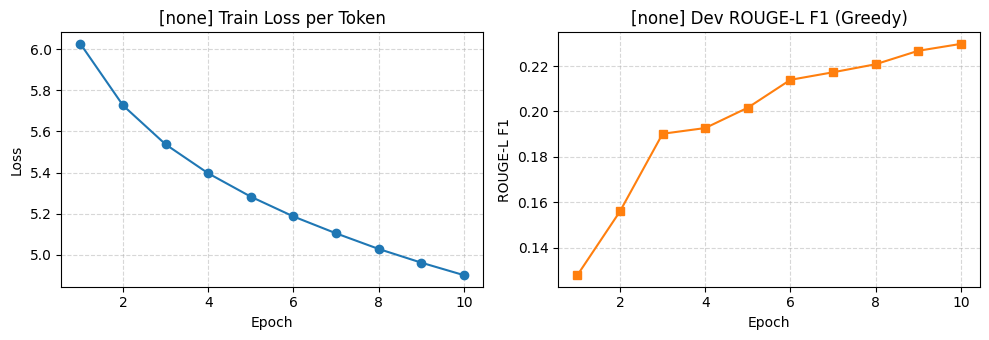

=== 3 CÂU DỊCH MẪU TRÊN TẬP TEST CỦA MÔ HÌNH [NONE] ===

Mẫu #1 (Test Index=89 | Độ dài câu nguồn=10 từ | ROUGE-L F1=0.3333):
  - Câu nguồn (EN)     : first on the docket is the maternal impression myth .
  - Tham chiếu (VI)    : đầu tiên là những truyền kỳ về dấu ấn từ người mẹ .
  - Mô hình dịch (HYP) : đầu tiên đầu tiên là một là một một của .

Mẫu #2 (Test Index=38 | Độ dài câu nguồn=36 từ | ROUGE-L F1=0.1319):
  - Câu nguồn (EN)     : this ban persecuting peaceful persons for mere acts of worship clearly violates the fundamental right to religious freedom and with it international human rights standards as also guaranteed by the constitution of the russian federation .
  - Tham chiếu (VI)    : việc cấm đoán này khiến những người hiền hoà bị bắt bớ chỉ vì các hoạt động thờ phượng , và rõ ràng vi phạm quyền tự do tôn giáo căn bản và tiêu chuẩn nhân quyền quốc tế cũng được quy định trong hiến pháp liên bang nga .
  - Mô hình dịch (HYP) : những thống này này đã được được một một của c

In [84]:
# Khởi tạo nơi lưu trữ kết quả chung cho cả 3 bài
trained_models = {}
all_histories = {}
best_epochs_dict = {}

def run_bai_1_no_attention():
    seed_all(42)
    model_none = build_seq2seq_model('none')
    num_params = sum(p.numel() for p in model_none.parameters())
    print(f"Bài 1 (Không Attention) | Tổng số tham số: {num_params:,}")
    
    hist, best_ep = train_and_validate(model_none, 'none')
    trained_models['none'] = model_none
    all_histories['none'] = hist
    best_epochs_dict['none'] = best_ep
    
    # Vẽ đồ thị học tập của Bài 1
    plot_single_learning_curve(hist, 'none')
    return model_none

model_b1 = run_bai_1_no_attention()

# Chọn cố định 3 câu mẫu từ tập Test để đối chiếu xuyên suốt cả 3 bài
SAMPLE_TEST_INDICES = select_sample_indices(model_b1, filtered['test'])
samples_b1 = inspect_sample_translations(model_b1, filtered['test'], SAMPLE_TEST_INDICES, 'none')

#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Toàn bộ các chỉ số, đồ thị huấn luyện và 3 câu dịch mẫu + nhận xét tương tự Bài 1
* Trực quan hóa Attention Heatmap: Vẽ 3 heatmap tương ứng với 3 câu dịch mẫu ở trên (trục tun là các token tiếng Việt sinh ra tính đến <eos>, trục hoành là các token tiếng Anh nguồn tính đến <eos>), kiểm tra tổng trọng số mỗi hàng bằng 1.0, và nhận xét căn chỉnh từ (word allignment)
* Lưu ý: không cần lưu file pt nào hết - chỉ cần output trên notebook

#### [Bài 2] 14. Huấn luyện, Đánh giá & Vẽ Heatmap Bahdanau (bahdanau)

Bài 2 (Bahdanau Attention) | Tổng số tham số: 8,025,763
[bahdanau] Epoch  1/10 | Train Loss: 6.0413 | Dev ROUGE-L: 0.1413 | Dev BLEU: 0.17 | Time: 105.3s
[bahdanau] Epoch  2/10 | Train Loss: 5.6456 | Dev ROUGE-L: 0.1985 | Dev BLEU: 1.17 | Time: 105.0s
[bahdanau] Epoch  3/10 | Train Loss: 5.3636 | Dev ROUGE-L: 0.2175 | Dev BLEU: 1.65 | Time: 104.8s
[bahdanau] Epoch  4/10 | Train Loss: 5.1682 | Dev ROUGE-L: 0.2445 | Dev BLEU: 2.39 | Time: 104.8s
[bahdanau] Epoch  5/10 | Train Loss: 4.9980 | Dev ROUGE-L: 0.2525 | Dev BLEU: 2.69 | Time: 104.7s
[bahdanau] Epoch  6/10 | Train Loss: 4.8640 | Dev ROUGE-L: 0.2721 | Dev BLEU: 3.49 | Time: 105.0s
[bahdanau] Epoch  7/10 | Train Loss: 4.7457 | Dev ROUGE-L: 0.2755 | Dev BLEU: 3.51 | Time: 105.0s
[bahdanau] Epoch  8/10 | Train Loss: 4.6416 | Dev ROUGE-L: 0.2856 | Dev BLEU: 3.85 | Time: 105.2s
[bahdanau] Epoch  9/10 | Train Loss: 4.5577 | Dev ROUGE-L: 0.2948 | Dev BLEU: 4.31 | Time: 110.8s
[bahdanau] Epoch 10/10 | Train Loss: 4.4777 | Dev ROUGE-L: 0.2

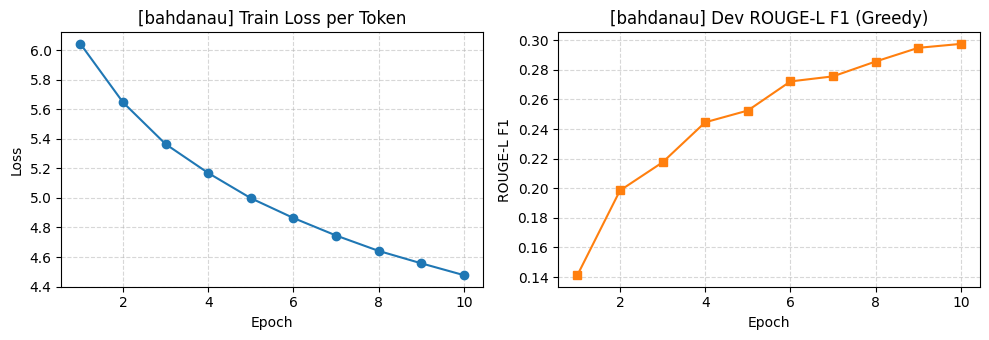

=== 3 CÂU DỊCH MẪU TRÊN TẬP TEST CỦA MÔ HÌNH [BAHDANAU] ===

Mẫu #1 (Test Index=89 | Độ dài câu nguồn=10 từ | ROUGE-L F1=0.3333):
  - Câu nguồn (EN)     : first on the docket is the maternal impression myth .
  - Tham chiếu (VI)    : đầu tiên là những truyền kỳ về dấu ấn từ người mẹ .
  - Mô hình dịch (HYP) : đầu tiên tiên là là là là của của của .

Mẫu #2 (Test Index=38 | Độ dài câu nguồn=36 từ | ROUGE-L F1=0.1895):
  - Câu nguồn (EN)     : this ban persecuting peaceful persons for mere acts of worship clearly violates the fundamental right to religious freedom and with it international human rights standards as also guaranteed by the constitution of the russian federation .
  - Tham chiếu (VI)    : việc cấm đoán này khiến những người hiền hoà bị bắt bớ chỉ vì các hoạt động thờ phượng , và rõ ràng vi phạm quyền tự do tôn giáo căn bản và tiêu chuẩn nhân quyền quốc tế cũng được quy định trong hiến pháp liên bang nga .
  - Mô hình dịch (HYP) : những này này <unk> <unk> <unk> <unk> cho nh

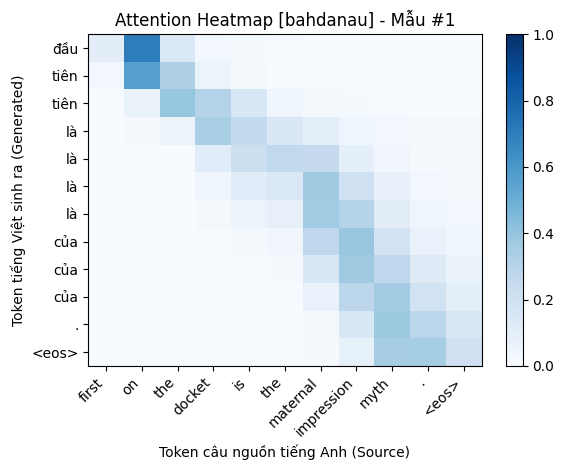

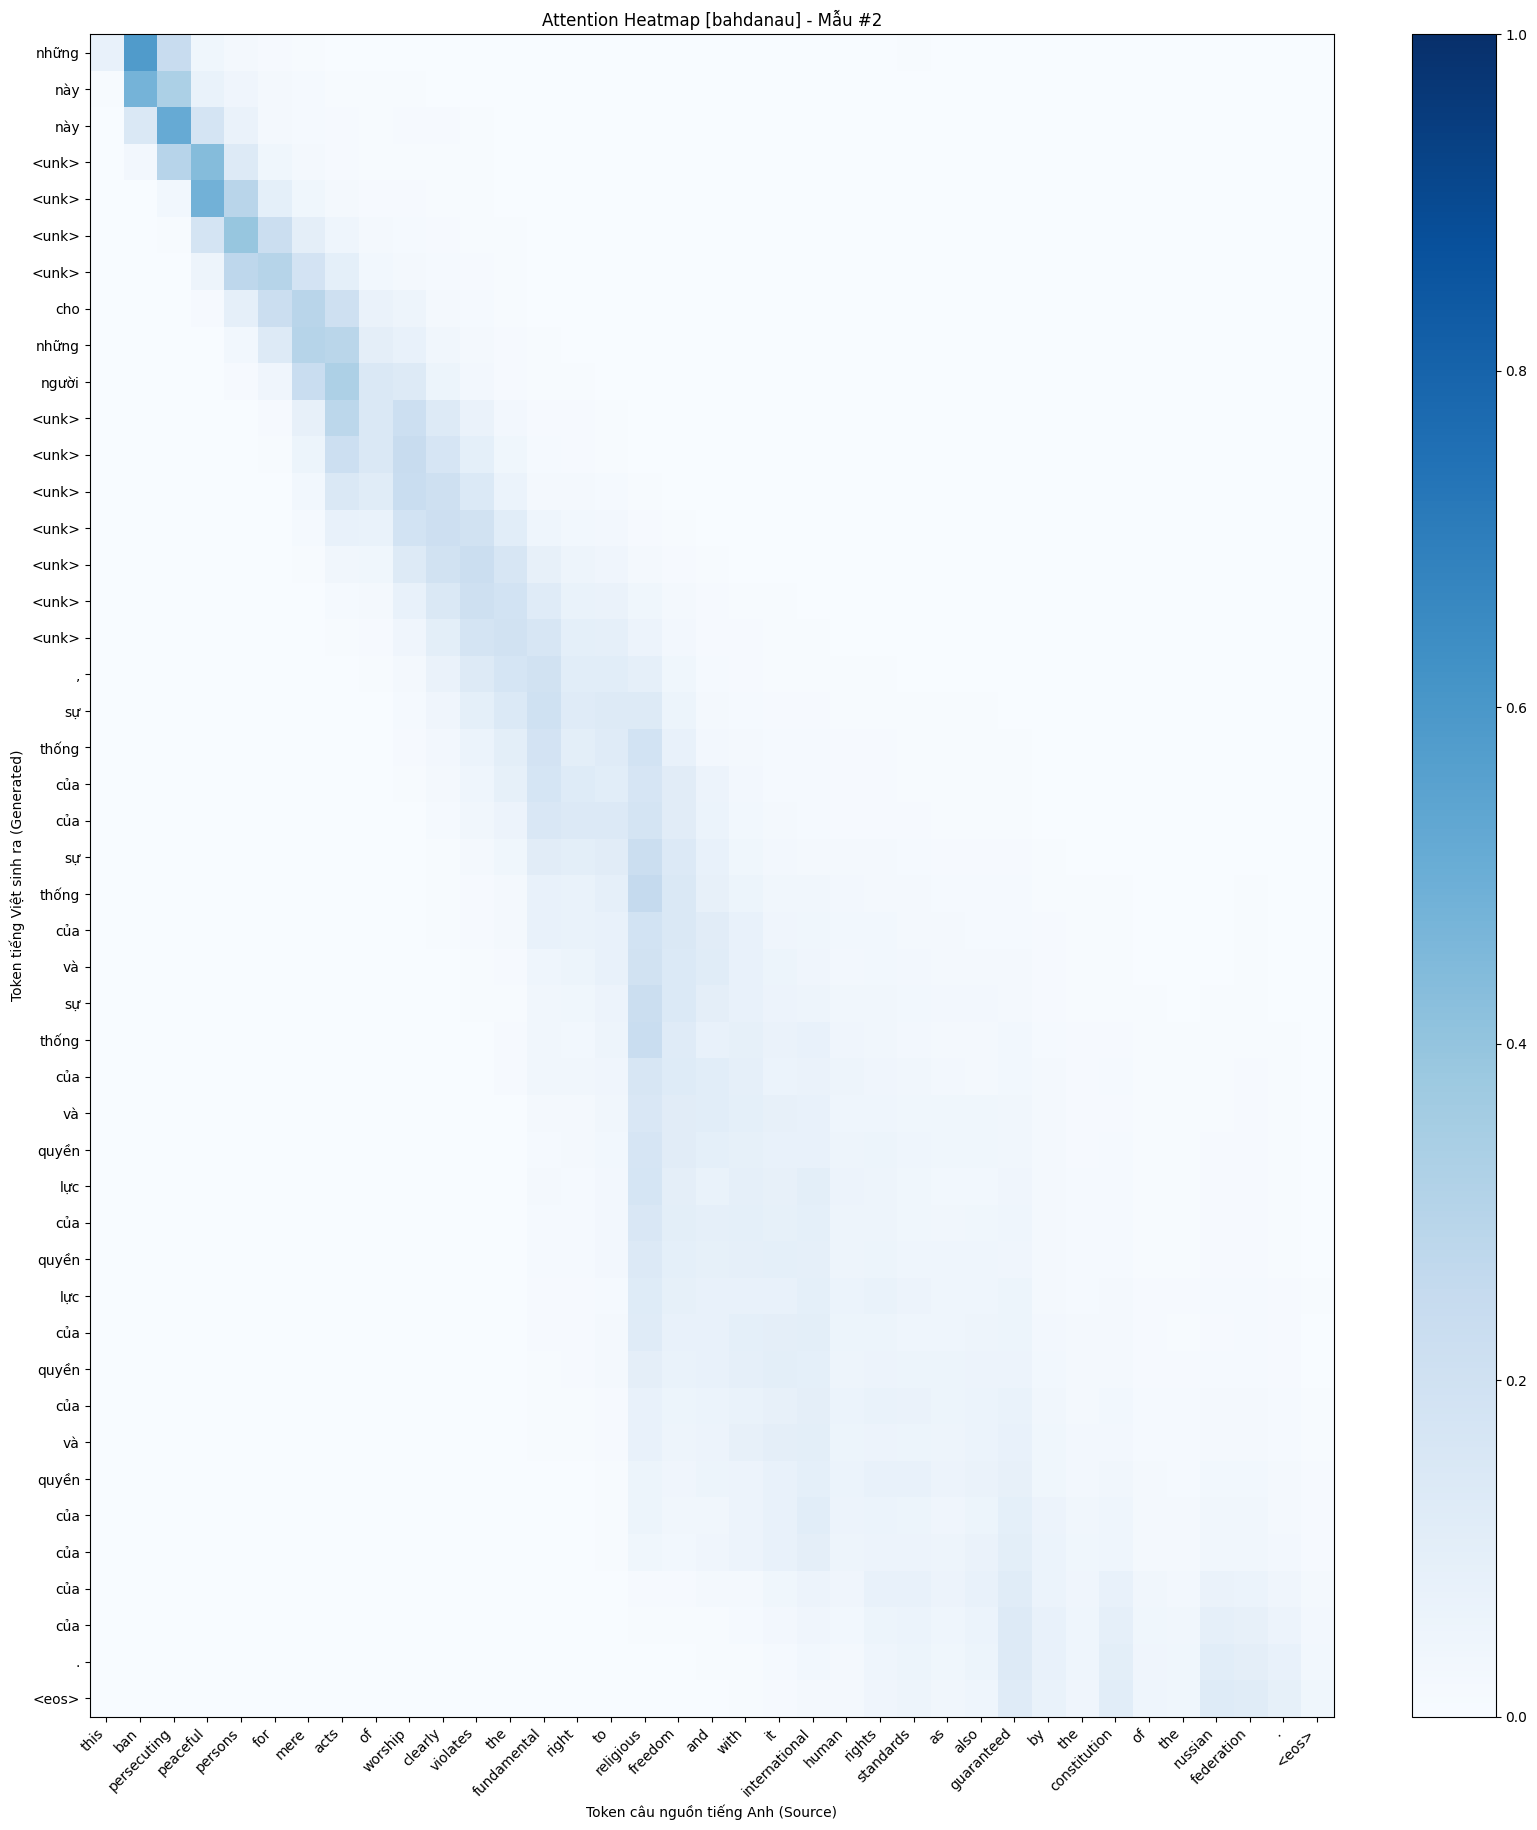

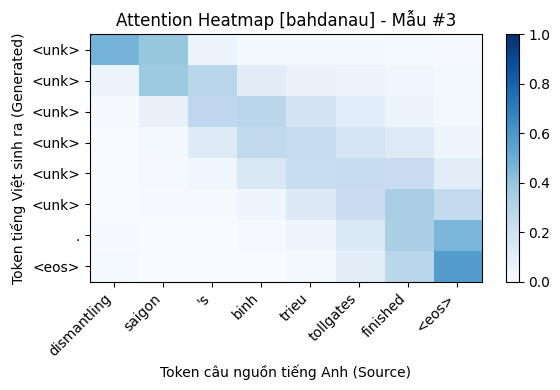

In [85]:
def run_bai_2_bahdanau():
    seed_all(42)
    model_bah = build_seq2seq_model('bahdanau')
    num_params = sum(p.numel() for p in model_bah.parameters())
    print(f"Bài 2 (Bahdanau Attention) | Tổng số tham số: {num_params:,}")
    
    hist, best_ep = train_and_validate(model_bah, 'bahdanau')
    trained_models['bahdanau'] = model_bah
    all_histories['bahdanau'] = hist
    best_epochs_dict['bahdanau'] = best_ep
    
    # Vẽ đồ thị học tập của Bài 2
    plot_single_learning_curve(hist, 'bahdanau')
    return model_bah

model_b2 = run_bai_2_bahdanau()

# In 3 câu dịch mẫu (cùng câu với Bài 1 để dễ so sánh) và vẽ 3 biểu đồ Heatmap
samples_b2 = inspect_sample_translations(model_b2, filtered['test'], SAMPLE_TEST_INDICES, 'bahdanau')
plot_sample_heatmaps(samples_b2, 'bahdanau')

#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

#### Yêu cầu đầu ra:
* Toàn bộ các chỉ số, đồ thị huấn luyện và 3 câu dịch mẫu + nhận xét tương tự bài 1
* Lưu trữ toàn bộ cấu hình, từ điển và lịch sử vào metadata.json (đang xem xét lại có cần thiết hay không)
* Bảng tổng hợp đối chiếu cả 3 mô hình: Lập bảng so sánh trực tiếp 3 kiến trúc của 3 bài (none, bahdanau, luong) trên các tiêu chí: ROUGE-L dev, ROUGE-L test, Số tham số, Giây/epoch, kèm đánh giá chuyên sao vì sao mô hình đó đạt kết quả tốt hơn (về mặt toán học, kiến trúc ghép nối và tốc độ hội tụ)

#### [Bài 3] 15. Huấn luyện & Đánh giá Luong Attention (luong)

Bài 3 (Luong Attention) | Tổng số tham số: 7,959,971
[luong   ] Epoch  1/10 | Train Loss: 6.0734 | Dev ROUGE-L: 0.1301 | Dev BLEU: 0.11 | Time: 103.0s
[luong   ] Epoch  2/10 | Train Loss: 5.7382 | Dev ROUGE-L: 0.1692 | Dev BLEU: 0.81 | Time: 98.3s
[luong   ] Epoch  3/10 | Train Loss: 5.5026 | Dev ROUGE-L: 0.1936 | Dev BLEU: 1.21 | Time: 103.1s
[luong   ] Epoch  7/10 | Train Loss: 4.8296 | Dev ROUGE-L: 0.2664 | Dev BLEU: 3.31 | Time: 104.7s
[luong   ] Epoch  8/10 | Train Loss: 4.7166 | Dev ROUGE-L: 0.2775 | Dev BLEU: 3.62 | Time: 103.0s
[luong   ] Epoch  9/10 | Train Loss: 4.6231 | Dev ROUGE-L: 0.2865 | Dev BLEU: 4.02 | Time: 102.1s
[luong   ] Epoch 10/10 | Train Loss: 4.5282 | Dev ROUGE-L: 0.2905 | Dev BLEU: 4.06 | Time: 105.5s
--> Đã lưu checkpoint tốt nhất của 'luong' tại epoch 10.



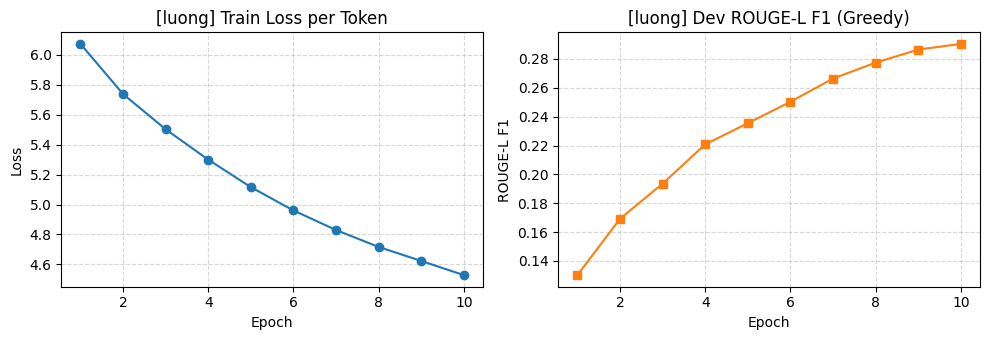

=== 3 CÂU DỊCH MẪU TRÊN TẬP TEST CỦA MÔ HÌNH [LUONG] ===

Mẫu #1 (Test Index=89 | Độ dài câu nguồn=10 từ | ROUGE-L F1=0.3333):
  - Câu nguồn (EN)     : first on the docket is the maternal impression myth .
  - Tham chiếu (VI)    : đầu tiên là những truyền kỳ về dấu ấn từ người mẹ .
  - Mô hình dịch (HYP) : đầu tiên đầu tiên là là là là sự của .

Mẫu #2 (Test Index=38 | Độ dài câu nguồn=36 từ | ROUGE-L F1=0.1188):
  - Câu nguồn (EN)     : this ban persecuting peaceful persons for mere acts of worship clearly violates the fundamental right to religious freedom and with it international human rights standards as also guaranteed by the constitution of the russian federation .
  - Tham chiếu (VI)    : việc cấm đoán này khiến những người hiền hoà bị bắt bớ chỉ vì các hoạt động thờ phượng , và rõ ràng vi phạm quyền tự do tôn giáo căn bản và tiêu chuẩn nhân quyền quốc tế cũng được quy định trong hiến pháp liên bang nga .
  - Mô hình dịch (HYP) : điều này này này <unk> <unk> những người người n

In [86]:
def run_bai_3_luong():
    seed_all(42)
    model_luong = build_seq2seq_model('luong')
    num_params = sum(p.numel() for p in model_luong.parameters())
    print(f"Bài 3 (Luong Attention) | Tổng số tham số: {num_params:,}")
    
    hist, best_ep = train_and_validate(model_luong, 'luong')
    trained_models['luong'] = model_luong
    all_histories['luong'] = hist
    best_epochs_dict['luong'] = best_ep
    
    # Vẽ đồ thị học tập của Bài 3
    plot_single_learning_curve(hist, 'luong')
    return model_luong

model_b3 = run_bai_3_luong()

# In 3 câu dịch mẫu của Luong (có thể vẽ thêm heatmap nếu muốn đưa vào báo cáo)
samples_b3 = inspect_sample_translations(model_b3, filtered['test'], SAMPLE_TEST_INDICES, 'luong')

#### [Evaluation] 16. Chấm điểm test & Bảng tổng hợp đánh giá

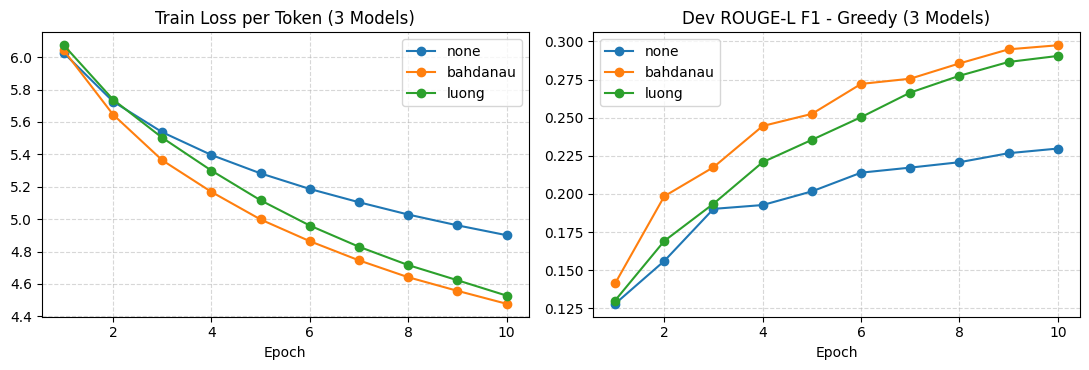

Lưu metadata.json và kiểm tra nạp lại checkpoint .pt: PASS

=== BẢNG TỔNG HỢP KẾT QUẢ PHẦN C (CHUẨN MỤC C.2) ===
               Mô hình  ROUGE-L dev  ROUGE-L test  BLEU test (tham khảo)  Best Epoch  Số tham số  Giây/epoch
Bài 1. Không attention       0.2298        0.2346                   2.63          10     7500963       67.09
       Bài 2. Bahdanau       0.2975        0.3138                   5.65          10     8025763      105.99
          Bài 3. Luong       0.2905        0.3054                   5.25          10     7959971      102.66


In [87]:
# 1. Hàm vẽ chung đường cong học tập của cả 3 mô hình trên cùng 1 biểu đồ
def plot_combined_curves(histories_dict):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for name, records in histories_dict.items():
        df = pd.DataFrame(records)
        axes[0].plot(df['epoch'], df['train_loss'], marker='o', label=name)
        axes[1].plot(df['epoch'], df['rougeL_f1'], marker='o', label=name)
        
    axes[0].set_title('Train Loss per Token (3 Models)')
    axes[1].set_title('Dev ROUGE-L F1 - Greedy (3 Models)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend()
        
    fig.tight_layout()
    fig.savefig(ART / 'learning_curves.png', dpi=150)
    plt.show()

# 2. Hàm lưu trữ toàn bộ thông tin thực nghiệm ra metadata.json và kiểm tra nạp lại checkpoint
def save_and_verify_checkpoints():
    meta_payload = {
        'config': cfg,
        'seed': 42,
        'device': str(device),
        'normalization': 'NFC; remove BOM; lowercase; whitespace',
        'src_vocab': src_vocab,
        'tgt_vocab': tgt_vocab,
        'selected_train_ids': [r['id'] for r in train_rows],
        'selected_dev_ids': [r['id'] for r in dev_rows],
        'histories': all_histories,
        'best_epochs': best_epochs_dict
    }
    (ART / 'metadata.json').write_text(
        json.dumps(meta_payload, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    
    # Kiểm tra khôi phục lại trọng số Bahdanau và đối chiếu logits
    reloaded_net = build_seq2seq_model('bahdanau')
    saved_state = torch.load(ART / 'bahdanau.pt', map_location=device, weights_only=True)
    reloaded_net.load_state_dict(saved_state)
    reloaded_net.eval()
    
    with torch.no_grad():
        s_in = sample_batch['src'].to(device)
        t_in = sample_batch['tgt'].to(device)
        lens = sample_batch['lengths']
        out_reloaded = reloaded_net(s_in, lens, t_in, teacher_ratio=1.0)
        out_current = trained_models['bahdanau'](s_in, lens, t_in, teacher_ratio=1.0)
        
    torch.testing.assert_close(out_reloaded, out_current)
    print("Lưu metadata.json và kiểm tra nạp lại checkpoint .pt: PASS\n")

# 3. Hàm chấm điểm tập Test một lần duy nhất và lập Bảng tổng hợp C.2
def evaluate_all_and_build_summary():
    model_labels = {
        'none': 'Bài 1. Không attention',
        'bahdanau': 'Bài 2. Bahdanau',
        'luong': 'Bài 3. Luong'
    }
    
    dev_summary, test_summary, final_table_rows = [], [], []
    
    for key in ['none', 'bahdanau', 'luong']:
        model = trained_models[key]
        hist = all_histories[key]
        
        # Điểm trên tập Dev và Test
        dev_res = evaluate_dataset(model, dev_rows)
        test_res = evaluate_dataset(model, filtered['test'])
        
        avg_sec = float(np.mean([ep_log['seconds'] for ep_log in hist]))
        param_count = sum(p.numel() for p in model.parameters())
        
        dev_summary.append({
            'model': key,
            'dev_rougeL': dev_res['rougeL_f1'],
            'dev_bleu': dev_res['bleu'],
            'best_epoch': best_epochs_dict[key],
            'parameters': param_count,
            'seconds_per_epoch': avg_sec
        })
        
        test_entry = {'model': key, **test_res}
        test_entry.pop('dev_nll', None)
        test_summary.append(test_entry)
        
        # Dòng dữ liệu chuẩn theo Bảng C.2 trong file Word
        final_table_rows.append({
            'Mô hình': model_labels[key],
            'ROUGE-L dev': round(dev_res['rougeL_f1'], 4),
            'ROUGE-L test': round(test_res['rougeL_f1'], 4),
            'BLEU test (tham khảo)': round(test_res['bleu'], 2),
            'Best Epoch': best_epochs_dict[key],
            'Số tham số': param_count,
            'Giây/epoch': round(avg_sec, 2)
        })
        
    pd.DataFrame(dev_summary).to_csv(ART / 'comparison_dev.csv', index=False)
    pd.DataFrame(test_summary).to_csv(ART / 'comparison_test.csv', index=False)
    
    summary_df = pd.DataFrame(final_table_rows)
    summary_df.to_csv(ART / 'part_c_summary_table.csv', index=False)
    
    print("=== BẢNG TỔNG HỢP KẾT QUẢ PHẦN C (CHUẨN MỤC C.2) ===")
    print(summary_df.to_string(index=False))
    return summary_df

# Thực thi tổng kết
plot_combined_curves(all_histories)
save_and_verify_checkpoints()
final_summary_df = evaluate_all_and_build_summary()